<h1>TensorFlow Convolutional Autoencoder</h1>


Importing libraries:

In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

print(tf.__version__)
!python --version

2.13.0
Python 3.10.12


Loading and procesing datasets

In [3]:
(train_images,_), (test_images,_) = tf.keras.datasets.mnist.load_data()

train_images = train_images.astype('float32') / 255.
test_images = test_images.astype('float32') / 255.

train_images = train_images[..., tf.newaxis]
test_images = test_images[..., tf.newaxis]

print(train_images.shape)

train_size = 60000
batch_size = 20
test_size = 10000

train_dataset = (tf.data.Dataset.from_tensor_slices(train_images).shuffle(train_size).batch(batch_size))
test_dataset = (tf.data.Dataset.from_tensor_slices(test_images).shuffle(test_size).batch(batch_size))

11490434/11490434 [==============================] - 0s 0us/step
(60000, 28, 28, 1)


Visualize the data


(20, 28, 28, 1)


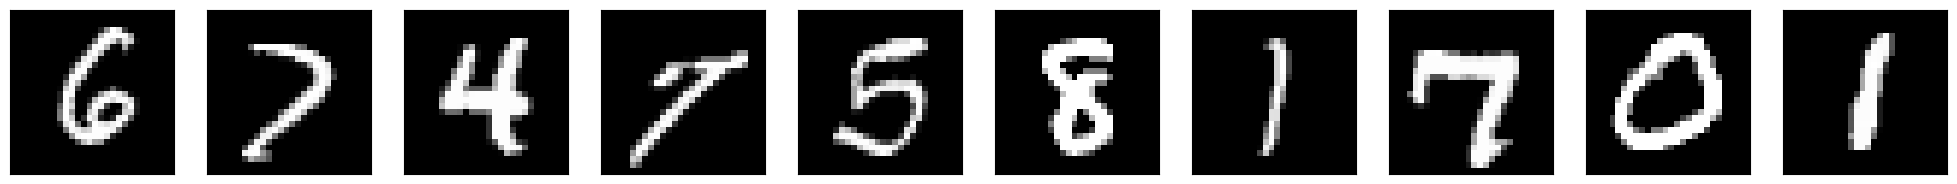

In [6]:
dataiter = iter(train_dataset)
images = next(dataiter)
print(images.shape)

n = 10
plt.figure(figsize=(25, 4))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    plt.imshow(tf.squeeze(images[i]), cmap='gray')

#plt.show()

Building the Encode-Decode network


In [ ]:
class AutoEncoder(tf.keras.Model):
  #Convolutional autoencoder

  def __init__(self):
    super(AutoEncoder, self).__init__()
    self.encoder = tf.keras.Sequential([
      tf.keras.layers.Input(shape=(28, 28, 1)),
      tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same'),
      tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'),
      tf.keras.layers.Conv2D(4, (3, 3), activation='relu', padding='same'),
      tf.keras.layers.MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid')])

    self.decoder = tf.keras.Sequential([
      tf.keras.layers.Conv2DTranspose(16, kernel_size=2, strides=2, activation='relu'),
      tf.keras.layers.Conv2DTranspose(1, kernel_size=2, strides=2, activation='sigmoid')])

  def call(self, x):
    encoded = self.encoder(x)
    decoded = self.decoder(encoded)
    return decoded

  def encode(self, x):
    return self.encoder(x)

  def decode(self, x):
    return self.decoder(x)

model = AutoEncoder()

Configure and train the model


In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss=tf.keras.losses.MeanSquaredError())
model.fit(train_images, train_images, batch_size=batch_size ,epochs=10, shuffle=False)

model.encoder.summary()
model.decoder.summary()

Epoch 1/10
3000/3000 [==============================] - 46s 15ms/step - loss: 0.0275
Epoch 2/10
3000/3000 [==============================] - 46s 15ms/step - loss: 0.0145
Epoch 3/10
3000/3000 [==============================] - 44s 15ms/step - loss: 0.0127
Epoch 4/10
3000/3000 [==============================] - 65s 22ms/step - loss: 0.0101
Epoch 5/10
3000/3000 [==============================] - 46s 15ms/step - loss: 0.0094
Epoch 6/10
3000/3000 [==============================] - 47s 16ms/step - loss: 0.0090
Epoch 7/10
3000/3000 [==============================] - 78s 26ms/step - loss: 0.0088
Epoch 8/10
3000/3000 [==============================] - 52s 17ms/step - loss: 0.0087
Epoch 9/10
3000/3000 [==============================] - 60s 20ms/step - loss: 0.0086
Epoch 10/10
3000/3000 [==============================] - 54s 18ms/step - loss: 0.0086
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param # 

Testing the model

(4, 7, 7)
tf.Tensor(
[[[2.9464047  2.9450884  2.9723315  2.96162    2.3898058  3.4384527
   3.0350149 ]
  [2.9464047  2.9490001  2.7669835  1.3845836  2.9527197  2.8878143
   3.0350149 ]
  [2.9464047  2.9314506  0.63917303 3.0246656  2.7298992  3.0089896
   3.0352778 ]
  [2.9464047  2.6373174  1.4944278  0.69628704 1.2338598  1.8323549
   3.385398  ]
  [2.9464047  2.743838   0.55383354 2.1882787  0.92646074 2.6277914
   3.0257776 ]
  [2.9464047  2.9176552  2.3427763  2.4881682  2.7050412  2.85408
   3.0355685 ]
  [2.9464047  3.0251517  3.2173805  2.8618512  2.8880923  2.8927543
   3.0350149 ]]

 [[3.5559654  3.500067   3.5073466  3.6474478  3.887684   4.022834
   3.5422313 ]
  [3.5559654  3.5149872  3.5275548  1.5087051  3.0115342  4.1049814
   3.5422313 ]
  [3.5559654  3.558655   2.057046   3.9162757  3.966233   3.6078374
   3.5422313 ]
  [3.5559654  3.4779317  1.6768811  3.8288736  2.9690242  3.6999056
   4.1088514 ]
  [3.5559654  3.1576018  1.4540701  3.0913723  2.5090308  2.6560342

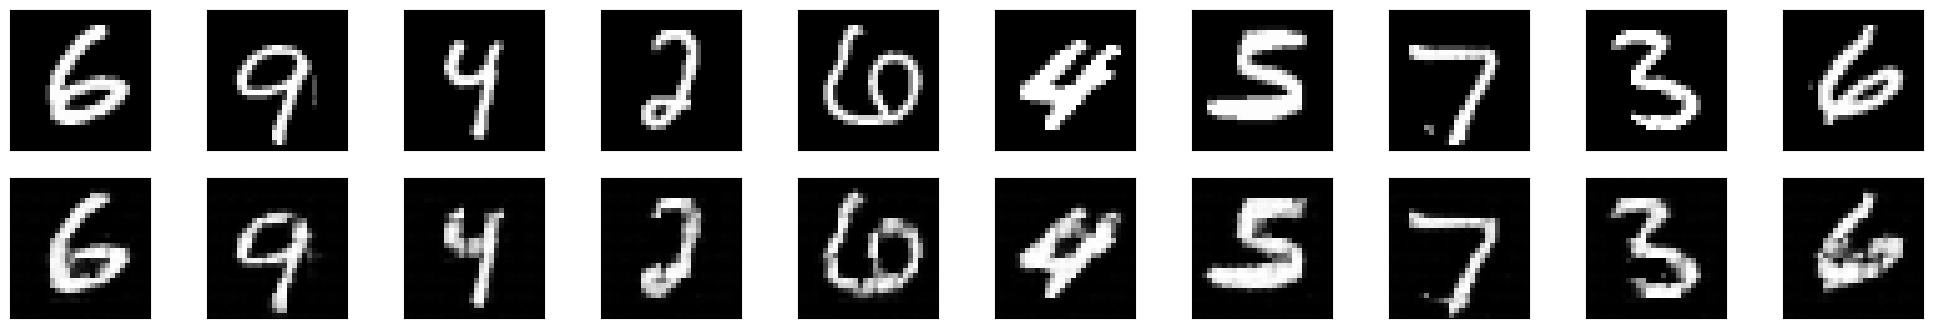

In [ ]:
# obtain one batch of test images
dataiter = iter(test_dataset)
images = next(dataiter)

latent = model.encode(images)
lat = tf.transpose(latent, perm=[0,3,1,2])
print(lat[0].shape)
print(lat[0])

# get sample outputs
output = model.decode(latent)
output = tf.transpose(output, perm=[0,3,1,2])
# prep images for display

# execute all encode-decode process instead
#output = model.predict(images)
#output = tf.transpose(output, perm=[0,3,1,2])

images = images.numpy()

# plot the first ten input images and then reconstructed images
fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

# input images on top row, reconstructions on bottom
for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)


Saving the Model as Pytorch script, and run it

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(20, 4, 7, 7)
tf.Tensor(
[[[[2.9450884  2.9450884  2.96273    ... 2.9512799  3.0321386
    3.0350149 ]
   [2.94803    2.9197106  2.7173681  ... 1.6405342  3.3813198
    3.0350149 ]
   [2.9693613  2.8919797  2.830196   ... 1.5073783  3.1259935
    3.0350149 ]
   ...
   [2.996638   2.9526     2.8264902  ... 2.061211   3.0213368
    3.0350149 ]
   [1.3123256  0.61655545 1.6951616  ... 2.723933   2.8923128
    3.0350149 ]
   [3.1153615  2.97557    2.9360359  ... 2.8921502  2.8919046
    3.0350149 ]]

  [[3.5741072  3.503999   3.4997709  ... 3.7716622  3.5058124
    3.5422313 ]
   [3.4727266  3.5144577  2.4263868  ... 3.5515778  4.1199913
    3.5422313 ]
   [3.5562224  3.500067   3.2996955  ... 0.74643534 3.830094
    3.5422313 ]
   ...
   [3.5772116  3.958689   3.702901   ... 0.64294434 3.93434
    3.5422313 ]
   [3.4633226  2.740599   0.6954795  ... 3.8504393  3.9747574
    3.5422313 ]
   [3.6171453  3.5581605  3.4729521  ... 3.532593   3.500067
    3.6010165 ]]

  [[4.330298   4.227406  

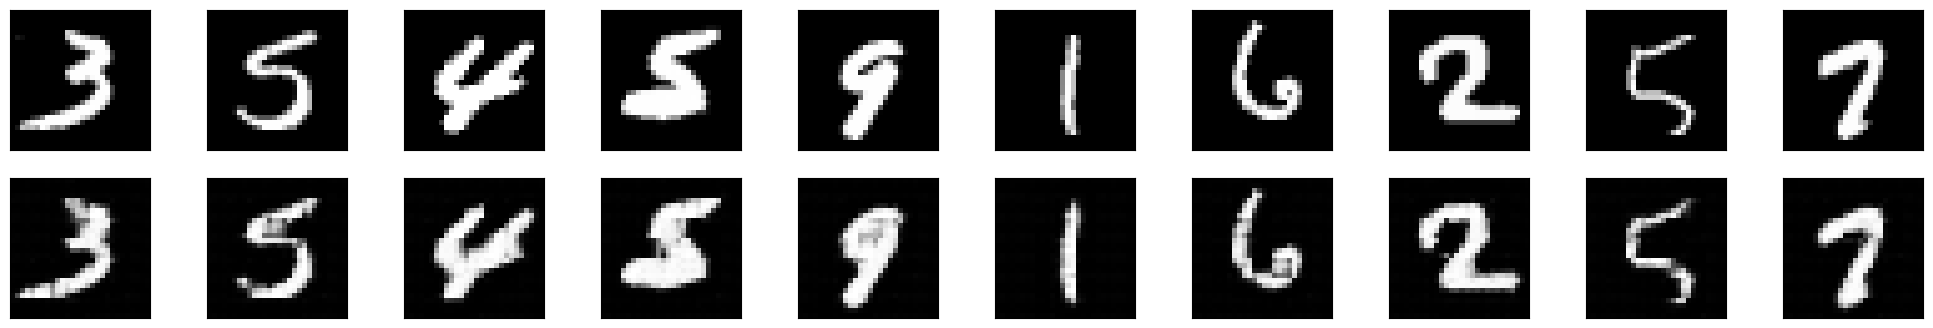

In [ ]:
#Mouting colab with the drive
from google.colab import drive
drive.mount('/content/drive')
base_location = '/content/drive/My Drive/Colab Notebooks/Autoencoder'

#model.encoder.save(base_location+'/TensorFlow/MNIST_CAE/Encoder_model')
tf.saved_model.save(model.encoder, base_location+'/TensorFlow/MNIST_CAE/Encoder_model')
savedModel = tf.saved_model.load(base_location+'/TensorFlow/MNIST_CAE/Encoder_model')

# obtain one batch of test images
images = next(dataiter)

#using SavedModel to get latent vector
latent = savedModel(images)
lat = tf.transpose(latent, perm=[0,3,1,2])
print(lat.shape)
print(lat)

#using original decoder model part
output = model.decode(latent)
output = tf.transpose(output, perm=[0,3,1,2])
images = images.numpy()
fig, axes = plt.subplots(nrows=2, ncols=10, sharex=True, sharey=True, figsize=(25,4))

for images, row in zip([images, output], axes):
    for img, ax in zip(images, row):
        ax.imshow(np.squeeze(img), cmap='gray')
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)




